# Ориентация текста 0° vs 180°: анализ амплитуды и фазы спектра

**Задача:** для 20 000 кропов с текстом предсказать `p_180` (вероятность того, что текст перевёрнут). Метрика: `1 - Brier`. Обучающей разметки нет.

**Что делаем в блокноте:**
1. Смотрим на данные.
2. Теория: что делает поворот на 180° с Фурье-спектром. Проверяем численно на реальных картинках.
3. Генерируем размеченную синтетику (рендерим русский и латинский текст системными шрифтами) и на ней проверяем гипотезы о том, какие признаки несут информацию об ориентации.
4. Переносим признаки на реальный тест и проверяем их **без разметки**: через согласованность независимых признаков, бимодальность и визуальную проверку.

Ручная разметка теста не используется.

In [2]:
import os, glob, random, time, io, warnings
import numpy as np, pandas as pd
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 90

DATA = '../Test (1)/test/images'
files = sorted(glob.glob(f'{DATA}/*.png'))
print(len(files), 'images')

def load_gray(p):
    return np.asarray(Image.open(p).convert('L'), dtype=np.float32) / 255.

def rot(x):
    return x[::-1, ::-1]

rng = np.random.default_rng(0)
random.seed(0)

20000 images


## 1. Данные

,count,mean,std,min,5%,25%,50%,75%,95%,max
w,20000.0,357.6,318.9,25.0,61.0,129.0,238.0,479.2,1047.0,1599.0
h,20000.0,64.4,59.3,10.0,16.0,27.0,42.0,76.0,195.0,492.0
aspect,20000.0,6.2,4.3,0.7,2.3,3.5,4.9,7.5,14.4,49.7


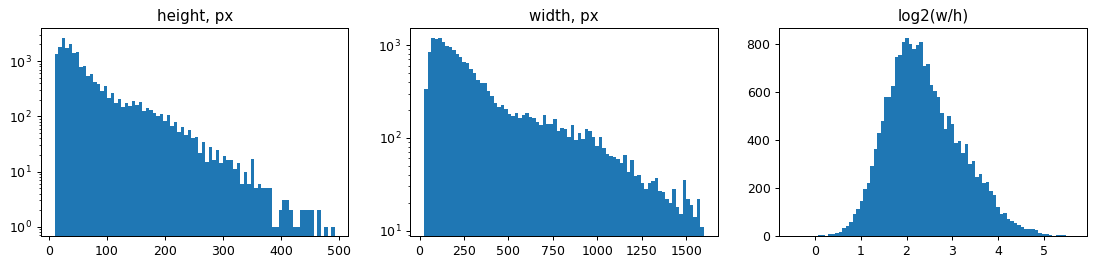

In [3]:
sizes = np.array([Image.open(f).size for f in files])
df_sz = pd.DataFrame({'w': sizes[:, 0], 'h': sizes[:, 1]})
df_sz['aspect'] = df_sz.w / df_sz.h
display(df_sz.describe(percentiles=[.05, .25, .5, .75, .95]).T.round(1))

fig, ax = plt.subplots(1, 3, figsize=(15, 3))
ax[0].hist(df_sz.h, bins=80, log=True); ax[0].set_title('height, px')
ax[1].hist(df_sz.w, bins=80, log=True); ax[1].set_title('width, px')
ax[2].hist(np.log2(df_sz.aspect), bins=80); ax[2].set_title('log2(w/h)')
plt.show()

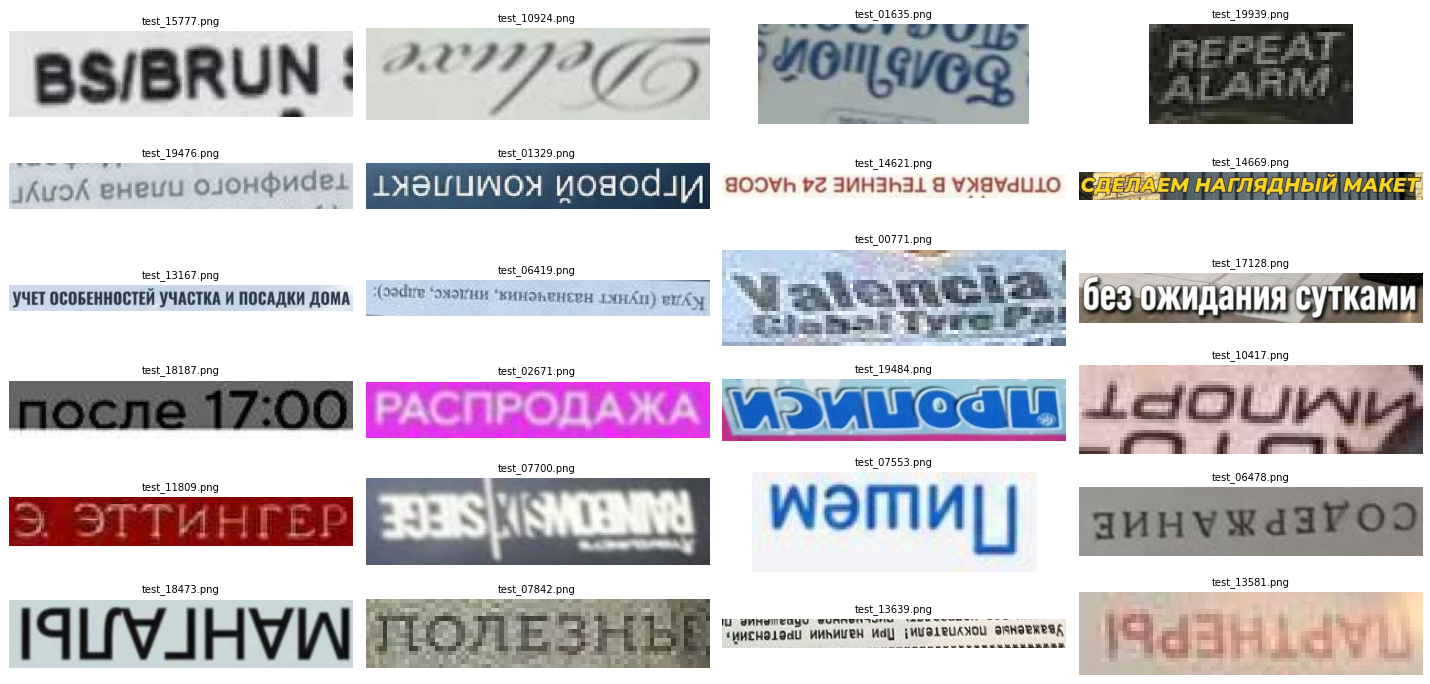

In [36]:
def show_grid(paths, ncol=4, titles=None, h=1.3):
    n = len(paths); nrow = int(np.ceil(n / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(4 * ncol, h * nrow))
    for i, a in enumerate(np.atleast_1d(ax).ravel()):
        a.axis('off')
        if i < n:
            im = paths[i] if isinstance(paths[i], np.ndarray) else Image.open(paths[i])
            a.imshow(im, cmap='gray' if isinstance(im, np.ndarray) else None)
            a.set_title(titles[i] if titles else os.path.basename(paths[i]) if isinstance(paths[i], str) else '', fontsize=8)
    plt.tight_layout(); plt.show()

show_grid(random.sample(files, 24))

По выборке видно, что перевёрнутых картинок много, на глаз около половины. Кропы разные: вывески, скриншоты, номера, рукописный текст. Встречается и КАПС, и строчные, и латиница, и кириллица. Есть обе полярности: тёмный текст на светлом и светлый на тёмном.

## 2. Теория: поворот на 180° в частотной области

Поворот на 180° означает $x'(n) = x(N-1-n)$ (по обеим осям). Для вещественного $x$ получаем

$$X'(k) = \sum_n x(N-1-n)\,e^{-2\pi i kn/N} = e^{-2\pi i k (N-1)/N}\;\overline{X(k)}.$$

Отсюда:

* **Амплитуда инвариантна:** $|X'(k)| = |X(k)|$ точно. Значит, **любой** признак, который зависит только от амплитудного спектра (энергия по частотам, спектр мощности, автокорреляция $=\mathcal F^{-1}|X|^2$, «текстура», статистики Габор-энергии), **не несёт никакой информации** об ориентации.
* **Фаза меняет знак** с линейной добавкой. Если взять **центрированный** спектр $X_c(k)=X(k)\,e^{\pi i k (N-1)/N}$ (начало координат в центре картинки), то $X'_c = \overline{X_c}$:
  * $\mathrm{Re}\,X_c$ чётная, при повороте не меняется;
  * $\mathrm{Im}\,X_c$ нечётная, при повороте **меняет знак**. Это ровно спектр нечётной части картинки $x_{odd} = (x - \mathrm{rot}(x))/2$.

**Итог:** вся информация об ориентации лежит в нечётной части изображения, то есть в $\mathrm{Im}\,X_c$ (фазе). Проверим это численно на реальных картинках.

In [5]:
def centered_fft2(x):
    H, W = x.shape
    X = np.fft.fft2(x)
    ky = np.fft.fftfreq(H, 1 / H)[:, None]
    kx = np.fft.fftfreq(W, 1 / W)[None, :]
    return X * np.exp(1j * np.pi * (ky * (H - 1) / H + kx * (W - 1) / W))

amp_err, conj_err, ph_err = [], [], []
for f in random.sample(files, 300):
    x = load_gray(f)
    X, Xr = np.fft.fft2(x), np.fft.fft2(rot(x))
    amp_err.append(np.abs(np.abs(X) - np.abs(Xr)).max() / np.abs(X).max())
    Xc, Xcr = centered_fft2(x), centered_fft2(rot(x))
    conj_err.append(np.abs(Xcr - np.conj(Xc)).max() / np.abs(Xc).max())
print(f'max rel |X|-|X_rot|          : {max(amp_err):.2e}   (амплитуда совпадает до машинной точности)')
print(f'max rel |X_c(rot) - conj X_c| : {max(conj_err):.2e}   (центрированная фаза просто меняет знак)')

max rel |X|-|X_rot|          : 4.44e-08   (амплитуда совпадает до машинной точности)
max rel |X_c(rot) - conj X_c| : 3.28e-08   (центрированная фаза просто меняет знак)


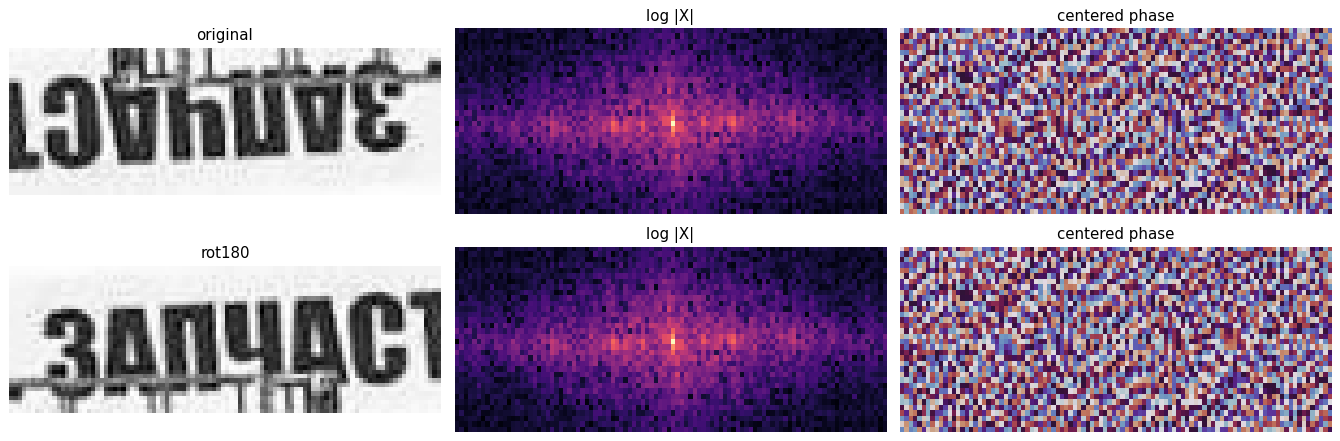

In [6]:
# Наглядно: амплитуда одна и та же, фаза зеркальная
x = load_gray(files[4402]) if len(files) > 4402 else load_gray(files[0])
fig, ax = plt.subplots(2, 3, figsize=(15, 5))
for r, img in enumerate([x, rot(x)]):
    Xc = centered_fft2(img)
    ax[r, 0].imshow(img, cmap='gray'); ax[r, 0].set_title(['original', 'rot180'][r])
    ax[r, 1].imshow(np.fft.fftshift(np.log1p(np.abs(Xc))), cmap='magma', aspect='auto'); ax[r, 1].set_title('log |X|')
    ax[r, 2].imshow(np.fft.fftshift(np.angle(Xc)), cmap='twilight', aspect='auto'); ax[r, 2].set_title('centered phase')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

### Следствие: глобальная гистограмма знаковых градиентов путает «повёрнуто» с «инвертированной полярностью»

При повороте на 180° вектор градиента меняет знак: $\nabla x'(n) = -\nabla x(N-1-n)$. При инверсии $1-x$ градиент тоже меняет знак, но остаётся на месте. Значит, **любая статистика, не зависящая от положения** (гистограмма ориентаций, HOG, усреднённый по картинке), даёт одно и то же для `rot(x)` и `1-x`. Поскольку в данных есть обе полярности, такие признаки без знания полярности бесполезны. Проверим.

In [7]:
def signed_grad_hist(x, bins=16):
    gy, gx = np.gradient(x)
    ang = np.arctan2(gy, gx); mag = np.hypot(gx, gy)
    h, _ = np.histogram(ang, bins=bins, range=(-np.pi, np.pi), weights=mag)
    return h / (h.sum() + 1e-9)

d_rot_inv, d_rot_orig = [], []
for f in random.sample(files, 300):
    x = load_gray(f)
    hr, hi, ho = signed_grad_hist(rot(x)), signed_grad_hist(1 - x), signed_grad_hist(x)
    d_rot_inv.append(np.abs(hr - hi).sum()); d_rot_orig.append(np.abs(hr - ho).sum())
print(f'L1(hist(rot x), hist(1-x)) : median {np.median(d_rot_inv):.2e}')
print(f'L1(hist(rot x), hist(x))   : median {np.median(d_rot_orig):.3f}')

L1(hist(rot x), hist(1-x)) : median 7.17e-04
L1(hist(rot x), hist(x))   : median 0.117


Отсюда первое практическое решение: работать с **картой «чернил» без знака полярности**:
фон оцениваем по рамке кропа, берём $m = |x - \mathrm{bg}|$. Эта карта эквивариантна повороту, $m(\mathrm{rot}\,x) = \mathrm{rot}\,m(x)$, и инвариантна к инверсии полярности.

## 3. Размеченная синтетика

Генерируем слова (кириллица и латиница, регистры `lower`, `Title`, `UPPER`, иногда цифры) 29 системными шрифтами. Случайно выбираем цвет и полярность, делаем **обрезку по чернилам с асимметричным случайным паддингом**, чтобы положение текста в кропе не выдавало ориентацию. Добавляем блюр, шум, JPEG, лёгкий наклон и даунскейл.

Каждый upright-пример входит в выборку в обеих ориентациях: $(x, 0)$ и $(\mathrm{rot}\,x, 1)$. Сплит делаем по id слова, чтобы пара не попала одновременно в train и в test.

upper     1903
lower     1603
title     1103
digits     391
Name: count, dtype: int64


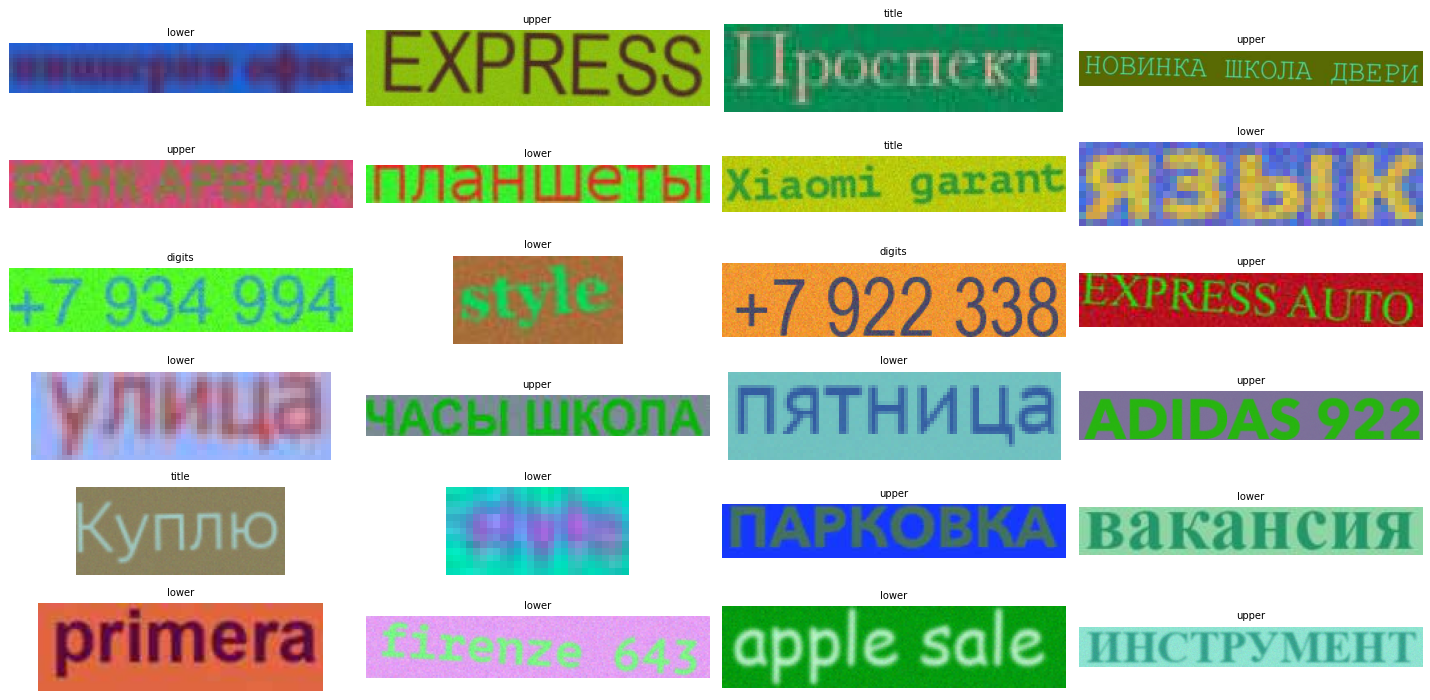

In [8]:
SUP = '/System/Library/Fonts/Supplemental/'
FONTS = [SUP + f for f in ['Arial.ttf', 'Arial Bold.ttf', 'Arial Narrow.ttf', 'Arial Black.ttf', 'Georgia.ttf',
         'Georgia Bold.ttf', 'Times New Roman.ttf', 'Times New Roman Bold.ttf', 'Verdana.ttf', 'Verdana Bold.ttf',
         'Tahoma.ttf', 'Tahoma Bold.ttf', 'Trebuchet MS.ttf', 'Trebuchet MS Bold.ttf', 'Courier New.ttf',
         'Courier New Bold.ttf', 'Impact.ttf', 'Comic Sans MS.ttf', 'Arial Italic.ttf', 'PTSans.ttc', 'PTMono.ttc',
         'Microsoft Sans Serif.ttf', 'Baskerville.ttc']] + \
        ['/System/Library/Fonts/Helvetica.ttc', '/System/Library/Fonts/Avenir Next.ttc', '/System/Library/Fonts/HelveticaNeue.ttc',
         os.path.expanduser('~/Library/Fonts/YS Text-Bold.ttf'), os.path.expanduser('~/Library/Fonts/YS Text-Light.ttf'),
         os.path.expanduser('~/Library/Fonts/Inter-VariableFont_slnt,wght.ttf')]
FONTS = [f for f in FONTS if os.path.exists(f)]

WORDS_RU = '''продам куплю доставка ремонт квартира аренда магазин продукты аптека салон красоты шиномонтаж
автосервис запчасти открыто закрыто вход выход касса скидка акция распродажа новинка цена рублей телефон
улица проспект переулок дом подъезд этаж офис склад парковка кафе ресторан пиццерия шаурма кофе хлеб молоко
овощи фрукты одежда обувь детский мир игрушки мебель кухни окна двери потолки ламинат плитка обои сантехника
электрика стройматериалы инструмент хозтовары цветы подарки ювелирный часы оптика стоматология клиника
медицинский центр банк банкомат почта связь интернет ноутбуки телефоны планшеты аксессуары чехлы зарядка
самовывоз оплата картой наличные перевозки грузчики такси работа требуются вакансия зарплата график
любознательный публикация коробка пиццы оригинал гарантия качество сервис бесплатно круглосуточно
понедельник пятница суббота воскресенье выходной обед часы работы продажа обмен кредит рассрочка
автомойка химчистка ателье парикмахерская маникюр фитнес бассейн школа курсы английский язык
ваше здоровье общество ограниченной ответственностью индивидуальный предприниматель'''.split()
WORDS_EN = '''sale open closed coffee shop market service garage parts delivery pizza bar hotel store fresh
premium original garant primera hyundai kefico unique firenze samsung apple xiaomi nike adidas zara
auto moto sport home style beauty studio market express center group city new best quality free'''.split()

def rand_text():
    r = random.random()
    words = WORDS_RU if r < 0.7 else WORDS_EN
    n = random.choice([1, 1, 1, 2, 2, 3])
    t = ' '.join(random.choice(words) for _ in range(n))
    if random.random() < 0.12:
        t = random.choice([t + ' ' + str(random.randint(1, 999)), str(random.randint(10, 99999)),
                           '+7 ' + str(random.randint(900, 999)) + ' ' + str(random.randint(100, 999))])
    c = random.random()
    case = 'lower' if c < 0.35 else ('title' if c < 0.6 else 'upper')
    t = t.lower() if case == 'lower' else (t.capitalize() if case == 'title' else t.upper())
    if not any(ch.isalpha() for ch in t): case = 'digits'
    return t, case

def render(text):
    font = ImageFont.truetype(random.choice(FONTS), random.randint(28, 64))
    fg = np.random.randint(0, 256, 3); bg = np.random.randint(0, 256, 3)
    while np.abs(fg.astype(int) - bg).mean() < 60:
        bg = np.random.randint(0, 256, 3)
    l, t, r, b = font.getbbox(text)
    canvas = Image.new('RGB', (r - l + 40, b - t + 40), tuple(bg))
    ImageDraw.Draw(canvas).text((20 - l, 20 - t), text, font=font, fill=tuple(fg))
    if random.random() < 0.5:
        canvas = canvas.rotate(random.uniform(-4, 4), resample=Image.BILINEAR, fillcolor=tuple(bg))
    # tight crop по чернилам + асимметричный случайный паддинг
    a = np.abs(np.asarray(canvas, np.float32) - bg).sum(-1) > 30
    ys, xs = np.where(a)
    if len(ys) == 0: return None
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    hh = y1 - y0
    pad = lambda: int(hh * random.uniform(0.0, 0.3))
    img = canvas.crop((max(0, x0 - pad()), max(0, y0 - pad()), x1 + pad(), y1 + pad()))
    # деградации
    th = random.randint(12, 60)
    img = img.resize((max(8, int(img.width * th / img.height)), th), Image.BILINEAR)
    if random.random() < 0.4: img = img.filter(ImageFilter.GaussianBlur(random.uniform(0.3, 1.2)))
    arr = np.asarray(img, np.float32) + np.random.normal(0, random.uniform(0, 12), (img.height, img.width, 3))
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    if random.random() < 0.6:
        buf = io.BytesIO(); img.save(buf, 'JPEG', quality=random.randint(25, 90)); img = Image.open(buf).convert('RGB')
    return img

N_SYN = 5000
syn_imgs, syn_case = [], []
while len(syn_imgs) < N_SYN:
    t, c = rand_text(); im = render(t)
    if im is not None: syn_imgs.append(im); syn_case.append(c)
syn_case = np.array(syn_case)
print(pd.Series(syn_case).value_counts())
show_grid([np.asarray(im) for im in syn_imgs[:24]], titles=list(syn_case[:24]))

## 4. Признаки

Всё считаем на карте чернил $m$, приведённой к фиксированному размеру $32\times128$. Признаки делятся на две группы:

| группа | что внутри | поведение при rot180 |
|---|---|---|
| `EVEN_amp` | log-амплитуда низких частот 2D-спектра, aspect, средняя «чернильность» | инвариантны ⇒ по теории бесполезны |
| `ODD_prof_y` | вертикальный профиль: центроид, асимметрия, разница «резкость подъёма минус спада», $\mathrm{Im}$ гармоник 1..4 | меняют знак |
| `ODD_prof_x` | то же для горизонтального профиля (асимметрия лево/право) | меняют знак |
| `ODD_phase2d` | $\mathrm{Im}\,X_c(k_y,k_x)/X(0,0)$ для низких частот (полуплоскость) | меняют знак |

Для нечётных признаков берём логрег **без intercept** и без центрирования. Тогда $f(\mathrm{rot}\,x) = -f(x)$, и $p(\mathrm{rot}\,x) = 1 - p(x)$ выполняется **автоматически**. Это правильная симметрия задачи, модели не нужно её выучивать.

In [9]:
H, W = 32, 128

def ink_map(img, H=H, W=W):
    g = img.convert('L').resize((W, H), Image.BILINEAR)
    x = np.asarray(g, np.float32) / 255.
    border = np.concatenate([x[:2].ravel(), x[-2:].ravel(), x[:, :2].ravel(), x[:, -2:].ravel()])
    m = np.abs(x - np.median(border))
    return np.clip(m / (np.percentile(m, 99) + 1e-3), 0, 1)

def prof_feats(p):
    n = len(p); p = p / (p.sum() + 1e-9)
    c = np.arange(n) - (n - 1) / 2
    mu = (p * c).sum(); sd = np.sqrt((p * (c - mu) ** 2).sum()) + 1e-9
    skew = (p * (c - mu) ** 3).sum() / sd ** 3
    d = np.diff(p); rf = d.max() + d.min()
    k = np.arange(1, 5)
    F = np.fft.fft(p)[1:5] * np.exp(1j * np.pi * k * (n - 1) / n)
    return np.r_[mu / n, skew, rf * n, F.imag]

KMAX = 6
def phase2d_feats(m, K=KMAX):
    Xc = centered_fft2(m); dc = np.abs(Xc[0, 0]) + 1e-9
    out = []
    for ky in range(0, K + 1):
        for kx in range(-K, K + 1):
            if ky == 0 and kx <= 0: continue   # полуплоскость: X(-k) = conj X(k)
            out.append(Xc[ky, kx].imag / dc)
    return np.array(out)

def even_feats(m, img):
    A = np.log1p(np.abs(np.fft.fft2(m))[:6, :12]).ravel()
    return np.r_[A, np.log(img.width / img.height), m.mean()]

def all_feats(img):
    m = ink_map(img)
    py, px = prof_feats(m.mean(1)), prof_feats(m.mean(0))
    return dict(EVEN_amp=even_feats(m, img), ODD_prof_y=py, ODD_prof_x=px, ODD_phase2d=phase2d_feats(m))

def feats_table(imgs):
    rows = [all_feats(im) for im in imgs]
    return {k: np.stack([r[k] for r in rows]) for k in rows[0]}

t0 = time.time()
F_up = feats_table(syn_imgs)
F_rot = feats_table([im.rotate(180) for im in syn_imgs])
print(f'{time.time() - t0:.1f}s for {2 * N_SYN} images')

# проверка нечётности на синтетике: odd(rot) == -odd(x)
for k in F_up:
    rel = np.abs(F_rot[k] + F_up[k]).mean() / (np.abs(F_up[k]).mean() + 1e-9)
    rel_even = np.abs(F_rot[k] - F_up[k]).mean() / (np.abs(F_up[k]).mean() + 1e-9)
    print(f'{k:12s}  |f(rot)+f(x)|/|f| = {rel:.3f}   |f(rot)-f(x)|/|f| = {rel_even:.3f}')

2.7s for 10000 images
EVEN_amp      |f(rot)+f(x)|/|f| = 2.000   |f(rot)-f(x)|/|f| = 0.000
ODD_prof_y    |f(rot)+f(x)|/|f| = 0.000   |f(rot)-f(x)|/|f| = 2.000
ODD_prof_x    |f(rot)+f(x)|/|f| = 0.000   |f(rot)-f(x)|/|f| = 2.000
ODD_phase2d   |f(rot)+f(x)|/|f| = 0.000   |f(rot)-f(x)|/|f| = 2.000


In [11]:
ids = np.arange(N_SYN); rs = np.random.default_rng(1).permutation(ids)
tr_id, te_id = rs[:int(.7 * N_SYN)], rs[int(.7 * N_SYN):]

def XY(group, idx):
    g = group if isinstance(group, (list, tuple)) else [group]
    Xu = np.hstack([F_up[k][idx] for k in g]); Xr = np.hstack([F_rot[k][idx] for k in g])
    return np.vstack([Xu, Xr]), np.r_[np.zeros(len(idx)), np.ones(len(idx))], np.r_[syn_case[idx], syn_case[idx]]

def odd_model(C=1.0):
    return make_pipeline(StandardScaler(with_mean=False), LogisticRegression(fit_intercept=False, C=C, max_iter=3000))

def evaluate(group, model_fn, name=None):
    Xtr, ytr, _ = XY(group, tr_id); Xte, yte, cte = XY(group, te_id)
    mdl = model_fn().fit(Xtr, ytr); p = mdl.predict_proba(Xte)[:, 1]
    row = {'features': name or str(group), 'AUC': roc_auc_score(yte, p), '1-Brier': 1 - brier_score_loss(yte, p)}
    for c in ['lower', 'title', 'upper']:
        s = cte == c; row[f'1-Brier[{c}]'] = 1 - brier_score_loss(yte[s], p[s])
    return row, mdl, p

res = []
res.append(evaluate('EVEN_amp', lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), 'EVEN_amp (logreg)')[0])
res.append(evaluate('EVEN_amp', lambda: HistGradientBoostingClassifier(max_iter=200), 'EVEN_amp (GBM)')[0])
for g in ['ODD_prof_y', 'ODD_prof_x', 'ODD_phase2d', ['ODD_prof_y', 'ODD_prof_x'], ['ODD_prof_y', 'ODD_prof_x', 'ODD_phase2d']]:
    res.append(evaluate(g, odd_model)[0])
res_df = pd.DataFrame(res).set_index('features').round(3)
res_df

,AUC,1-Brier,1-Brier[lower],1-Brier[title],1-Brier[upper]
features,,,,,
EVEN_amp (logreg),0.500,0.750,0.750,0.750,0.750
EVEN_amp (GBM),0.500,0.749,0.749,0.749,0.749
ODD_prof_y,0.642,0.768,0.764,0.751,0.786
ODD_prof_x,0.664,0.769,0.774,0.789,0.770
ODD_phase2d,0.696,0.778,0.750,0.841,0.760
"['ODD_prof_y', 'ODD_prof_x']",0.713,0.784,0.782,0.793,0.798
"['ODD_prof_y', 'ODD_prof_x', 'ODD_phase2d']",0.756,0.798,0.781,0.851,0.789


**Проверка H0 (амплитуда бесполезна).** `EVEN_amp` даёт AUC ≈ 0.5 и 1-Brier ≈ 0.75, то есть уровень константы 0.5. Даже GBM ничего не находит. Теория подтверждается.

**H1 (информация в фазе и нечётной части).** Все `ODD_*`-группы заметно выше случайного уровня.

### H2. Сколько гармоник нужно? Какое минимальное разрешение?

Если сигнал сидит в низкочастотной фазе, то хватит маленького входа и нескольких гармоник. Тогда быстрая модель реальна.

H,8,16,32
K,,,
1,0.755,0.756,0.756
2,0.764,0.764,0.764
3,0.769,0.767,0.767
4,NaN,0.772,0.772
6,NaN,0.778,0.778
8,NaN,NaN,0.780
12,NaN,NaN,0.768


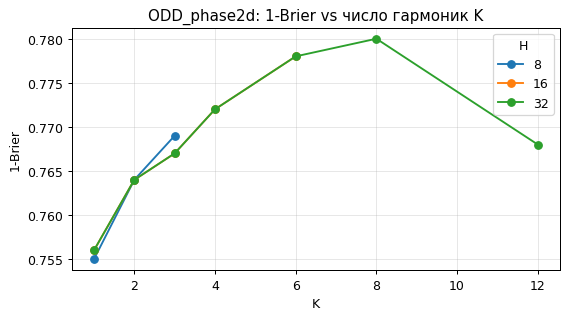

In [12]:
def phase_only_eval(Hs, Ks):
    out = []
    for Hh in Hs:
        Ww = Hh * 4
        Pu = [ink_map(im, Hh, Ww) for im in syn_imgs]
        for K in Ks:
            if K >= Hh // 2: continue
            fu = np.stack([phase2d_feats(m, K) for m in Pu])
            Xtr = np.vstack([fu[tr_id], -fu[tr_id]]); ytr = np.r_[np.zeros(len(tr_id)), np.ones(len(tr_id))]
            Xte = np.vstack([fu[te_id], -fu[te_id]]); yte = np.r_[np.zeros(len(te_id)), np.ones(len(te_id))]
            p = odd_model().fit(Xtr, ytr).predict_proba(Xte)[:, 1]
            out.append({'H': Hh, 'K': K, 'n_feat': fu.shape[1], '1-Brier': 1 - brier_score_loss(yte, p), 'AUC': roc_auc_score(yte, p)})
    return pd.DataFrame(out)

# f(rot x) = -f(x) выполняется точно (проверено выше), поэтому здесь используем -fu вместо повторного счёта
sweep = phase_only_eval([8, 16, 32], [1, 2, 3, 4, 6, 8, 12])
piv = sweep.pivot(index='K', columns='H', values='1-Brier').round(3)
display(piv)
piv.plot(marker='o', figsize=(7, 3.5), title='ODD_phase2d: 1-Brier vs число гармоник K'); plt.ylabel('1-Brier'); plt.grid(alpha=.3); plt.show()

### H3. Вертикальная асимметрия идёт от выносных элементов, поэтому КАПС почти симметричен

У строчных букв верхние выносные (б, в, д в рукописных формах, b, d, f, h, k, l, t) и нижние (р, у, д, ц, щ, g, p, q, y) распределены неравномерно, и базовая линия плоская. У заглавных букв этого почти нет. Смотрим на долю энергии нечётной части $\|m_{odd}\|^2/\|m - \bar m\|^2$ и на распределение центроида по регистрам.

,odd_2d,odd_prof_y,odd_prof_x,centroid_y
case,,,,
digits,0.461,0.233,0.453,-0.005
lower,0.411,0.229,0.466,-0.006
title,0.398,0.191,0.466,0.015
upper,0.438,0.229,0.473,-0.005


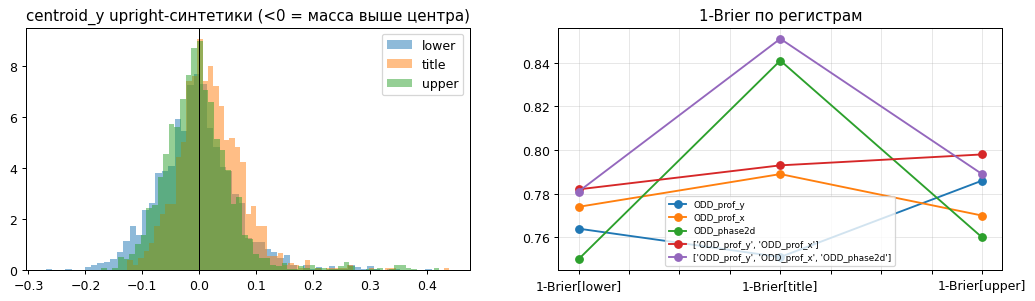

In [13]:
def odd_ratio(m):
    mc = m - m.mean(); o = (mc - rot(mc)) / 2
    return (o ** 2).sum() / ((mc ** 2).sum() + 1e-9)

def odd_ratio_axis(m, axis):
    p = m.mean(axis); p = p - p.mean(); o = (p - p[::-1]) / 2
    return (o ** 2).sum() / ((p ** 2).sum() + 1e-9)

syn_maps = [ink_map(im) for im in syn_imgs]
syn_or = pd.DataFrame({'case': syn_case,
                       'odd_2d': [odd_ratio(m) for m in syn_maps],
                       'odd_prof_y': [odd_ratio_axis(m, 1) for m in syn_maps],
                       'odd_prof_x': [odd_ratio_axis(m, 0) for m in syn_maps],
                       'centroid_y': F_up['ODD_prof_y'][:, 0]})
display(syn_or.groupby('case').median().round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for c in ['lower', 'title', 'upper']:
    ax[0].hist(syn_or.centroid_y[syn_or.case == c], bins=60, alpha=.5, density=True, label=c)
ax[0].axvline(0, c='k', lw=.8); ax[0].legend(); ax[0].set_title('centroid_y upright-синтетики (<0 = масса выше центра)')
pd.DataFrame(res_df[['1-Brier[lower]', '1-Brier[title]', '1-Brier[upper]']]).iloc[2:].T.plot(ax=ax[1], marker='o')
ax[1].set_title('1-Brier по регистрам'); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
plt.show()

### H4. Нелинейная модель на тех же нечётных признаках

Логрег на нечётных признаках линеен в фазовом пространстве. Проверим, помогает ли нелинейность. Антисимметрию обеспечим симметризацией: $p(x) = \tfrac12\big(g(x) + 1 - g(\mathrm{rot}\,x)\big)$.

In [14]:
grp = ['ODD_prof_y', 'ODD_prof_x', 'ODD_phase2d']
Xtr, ytr, _ = XY(grp, tr_id); Xte, yte, cte = XY(grp, te_id)
gbm = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05).fit(Xtr, ytr)
n = len(te_id)
g = gbm.predict_proba(Xte)[:, 1]
g_sym = 0.5 * (g + 1 - np.r_[g[n:], g[:n]])   # Xte = [up; rot] ⇒ rot-пара для i это i±n
lin = odd_model().fit(Xtr, ytr); p_lin = lin.predict_proba(Xte)[:, 1]
print(f'linear odd logreg : 1-Brier {1 - brier_score_loss(yte, p_lin):.3f}  AUC {roc_auc_score(yte, p_lin):.3f}')
print(f'GBM (raw)         : 1-Brier {1 - brier_score_loss(yte, g):.3f}  AUC {roc_auc_score(yte, g):.3f}')
print(f'GBM (symmetrized) : 1-Brier {1 - brier_score_loss(yte, g_sym):.3f}  AUC {roc_auc_score(yte, g_sym):.3f}')
print(f'consistency p(x)+p(rot x)-1: raw {np.abs(g[:n] + g[n:] - 1).mean():.3f}, sym {np.abs(g_sym[:n] + g_sym[n:] - 1).mean():.1e}')

linear odd logreg : 1-Brier 0.798  AUC 0.756
GBM (raw)         : 1-Brier 0.819  AUC 0.803
GBM (symmetrized) : 1-Brier 0.821  AUC 0.807
consistency p(x)+p(rot x)-1: raw 0.063, sym 2.2e-18


## 5. Реальный тест: проверки без разметки

Разметки нет, поэтому используем свойства, которые проверяются без неё:

1. **Домен-гэп:** сравниваем распределения $\|x_{odd}\|$ и прочих признаков на синтетике и на реальных данных.
2. **Бимодальность:** если нечётный признак информативен, а тест — смесь двух ориентаций, то распределение скора должно быть двугорбым.
3. **Согласованность независимых каналов.** Модель только по вертикальному профилю (`prof_y`) и модель только по горизонтальному (`prof_x`) смотрят на разные оси. Если **на реальном тесте** их знаки совпадают чаще 50%, значит обе ловят реальную ориентацию, а не шум синтетики.
4. **Оценка доли перевёрнутых.** Для нечётного скора $s$: $\mathbb E_{test}[s] = (1-2\pi)\,\mathbb E_{up}[s]$, отсюда грубая оценка $\pi$.
5. Визуальная проверка крайних и неуверенных примеров.

In [15]:
t0 = time.time()
test_imgs = [Image.open(f).convert('RGB') for f in files]
F_test = feats_table(test_imgs)
test_maps = [ink_map(im) for im in test_imgs]
print(f'{time.time() - t0:.1f}s for {len(files)} images  ({(time.time() - t0) / len(files) * 1e3:.2f} ms/img, python, 1 core)')

31.0s for 20000 images  (1.55 ms/img, python, 1 core)


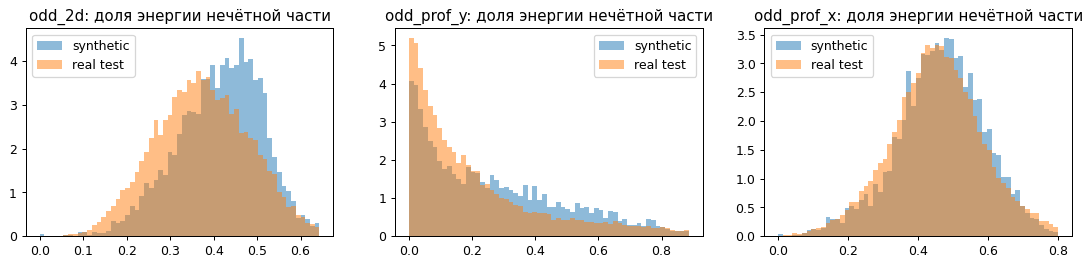

,synthetic,real
odd_2d,0.424,0.374
odd_prof_y,0.217,0.141
odd_prof_x,0.468,0.454


In [16]:
real_or = pd.DataFrame({'odd_2d': [odd_ratio(m) for m in test_maps],
                        'odd_prof_y': [odd_ratio_axis(m, 1) for m in test_maps],
                        'odd_prof_x': [odd_ratio_axis(m, 0) for m in test_maps]})
fig, ax = plt.subplots(1, 3, figsize=(15, 3))
for a, c in zip(ax, ['odd_2d', 'odd_prof_y', 'odd_prof_x']):
    b = np.linspace(0, np.percentile(np.r_[real_or[c], syn_or[c]], 99), 60)
    a.hist(syn_or[c], bins=b, alpha=.5, density=True, label='synthetic')
    a.hist(real_or[c], bins=b, alpha=.5, density=True, label='real test')
    a.set_title(f'{c}: доля энергии нечётной части'); a.legend()
plt.show()
display(pd.DataFrame({'synthetic': syn_or[['odd_2d', 'odd_prof_y', 'odd_prof_x']].median(),
                      'real': real_or.median()}).round(3))

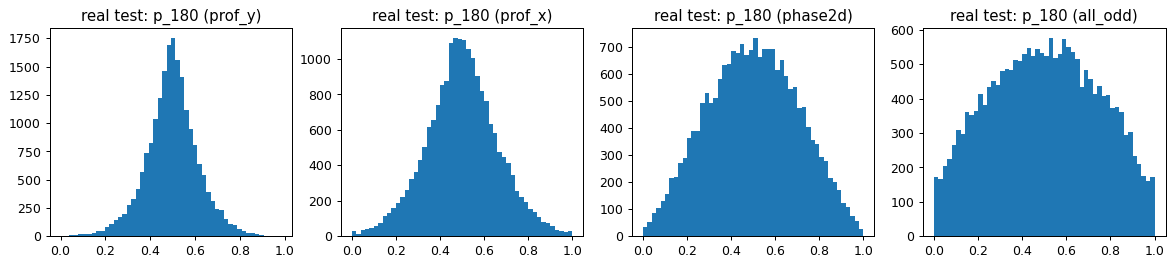

,pair,agree_synth,agree_real,spearman_real
0,prof_y vs prof_x,0.541,0.513,0.023
1,prof_y vs phase2d,0.597,0.540,0.086
2,prof_x vs phase2d,0.604,0.624,0.358


In [20]:
def fit_full(group):
    g = group if isinstance(group, list) else [group]
    Xa = np.vstack([np.hstack([F_up[k] for k in g]), np.hstack([F_rot[k] for k in g])])
    ya = np.r_[np.zeros(N_SYN), np.ones(N_SYN)]
    return odd_model().fit(Xa, ya), g

def score(model_g, F):
    m, g = model_g
    return m.predict_proba(np.hstack([F[k] for k in g]))[:, 1]

models = {n: fit_full(g) for n, g in {'prof_y': 'ODD_prof_y', 'prof_x': 'ODD_prof_x', 'phase2d': 'ODD_phase2d',
                                       'all_odd': ['ODD_prof_y', 'ODD_prof_x', 'ODD_phase2d']}.items()}
P_test = pd.DataFrame({n: score(m, F_test) for n, m in models.items()}, index=[os.path.basename(f)[:-4] for f in files])

fig, ax = plt.subplots(1, 4, figsize=(16, 3))
for a, c in zip(ax, P_test.columns):
    a.hist(P_test[c], bins=50); a.set_title(f'real test: p_180 ({c})')
plt.show()

# согласованность каналов: на синтетике (есть метки) и на реальном тесте (меток нет)
Xs = {n: np.vstack([np.hstack([F_up[k][te_id] for k in m[1]]), np.hstack([F_rot[k][te_id] for k in m[1]])]) for n, m in models.items()}
agree = lambda a, b: np.mean((a > .5) == (b > .5))
pairs = [('prof_y', 'prof_x'), ('prof_y', 'phase2d'), ('prof_x', 'phase2d')]
rows = []
for a, b in pairs:
    pa_s = models[a][0].predict_proba(Xs[a])[:, 1]; pb_s = models[b][0].predict_proba(Xs[b])[:, 1]
    rows.append({'pair': f'{a} vs {b}', 'agree_synth': agree(pa_s, pb_s), 'agree_real': agree(P_test[a], P_test[b]),
                 'spearman_real': stats.spearmanr(P_test[a], P_test[b]).correlation})
display(pd.DataFrame(rows).round(3))

Как читать таблицу. Если бы канал на реальных данных не нёс информации об ориентации, то `agree_real` было бы ≈ 0.5, а корреляция ≈ 0: у картинки и у её поворота знаки нечётных признаков противоположны, и шум двух разных осей не согласован. Значимое превышение 0.5 означает, что оба канала «видят» одну и ту же скрытую переменную, то есть ориентацию.

Ниже оценка доли перевёрнутых в тесте (грубая, опирается на калибровку по синтетике).

In [21]:
for n, m in models.items():
    s_up = 2 * m[0].predict_proba(np.hstack([F_up[k] for k in m[1]]))[:, 1] - 1   # E_up[s] на синтетике
    s_te = 2 * P_test[n] - 1
    pi = 0.5 * (1 - s_te.mean() / s_up.mean())
    print(f'{n:8s}: E_up[s]={s_up.mean():+.3f}  E_test[s]={s_te.mean():+.3f}  => доля rot180 ≈ {pi:.2f}')

prof_y  : E_up[s]=-0.064  E_test[s]=-0.004  => доля rot180 ≈ 0.47
prof_x  : E_up[s]=-0.087  E_test[s]=+0.001  => доля rot180 ≈ 0.51
phase2d : E_up[s]=-0.144  E_test[s]=-0.002  => доля rot180 ≈ 0.49
all_odd : E_up[s]=-0.225  E_test[s]=-0.002  => доля rot180 ≈ 0.50


Самые уверенные "upright" (p_180 → 0)


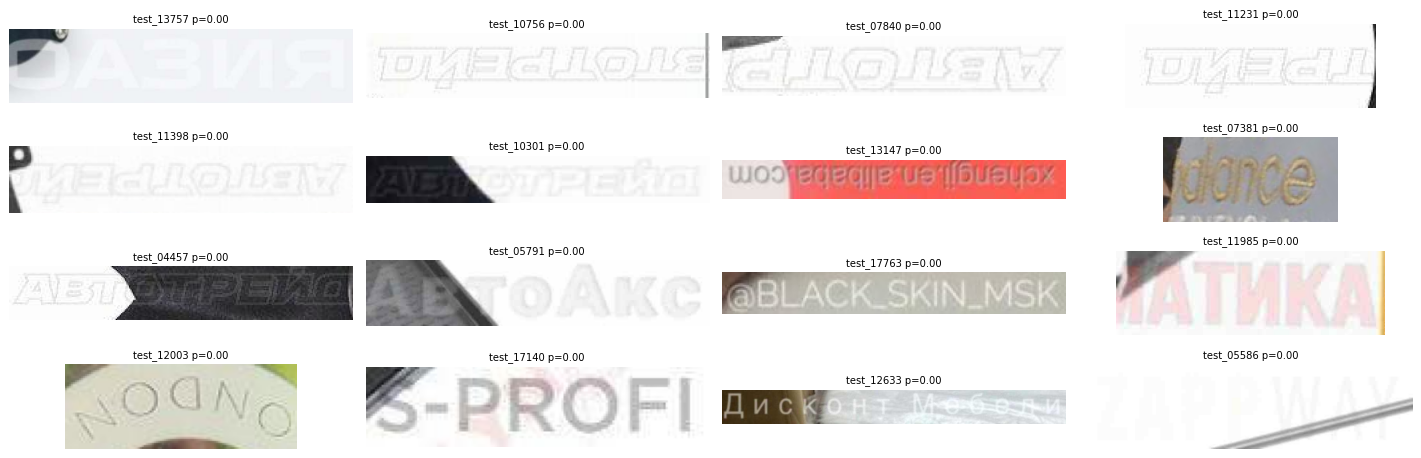

Самые уверенные "rot180" (p_180 → 1)


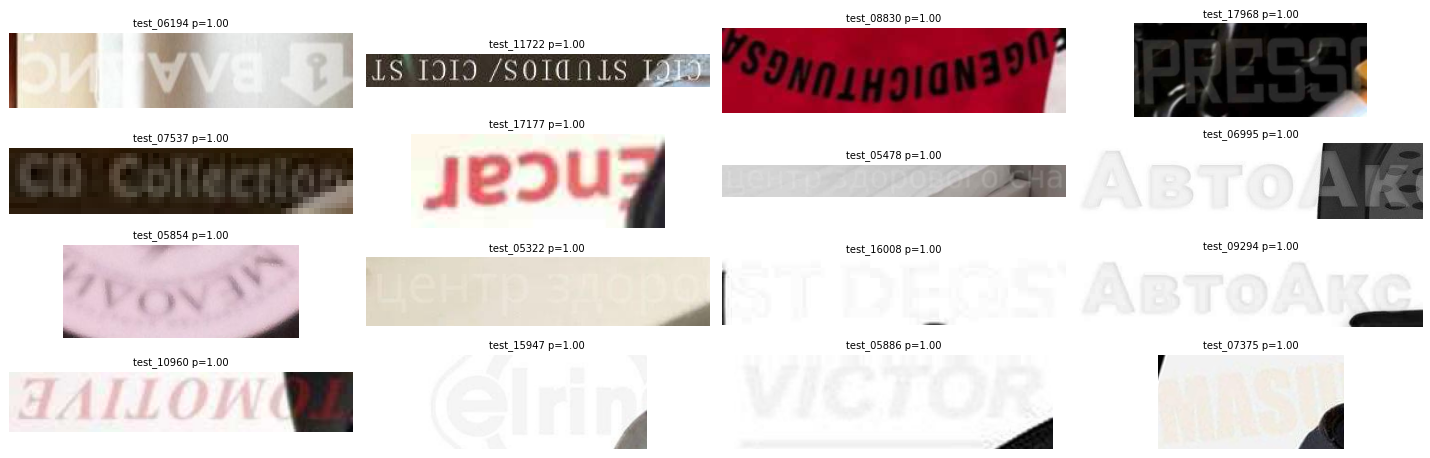

Самые неуверенные (p ≈ 0.5)


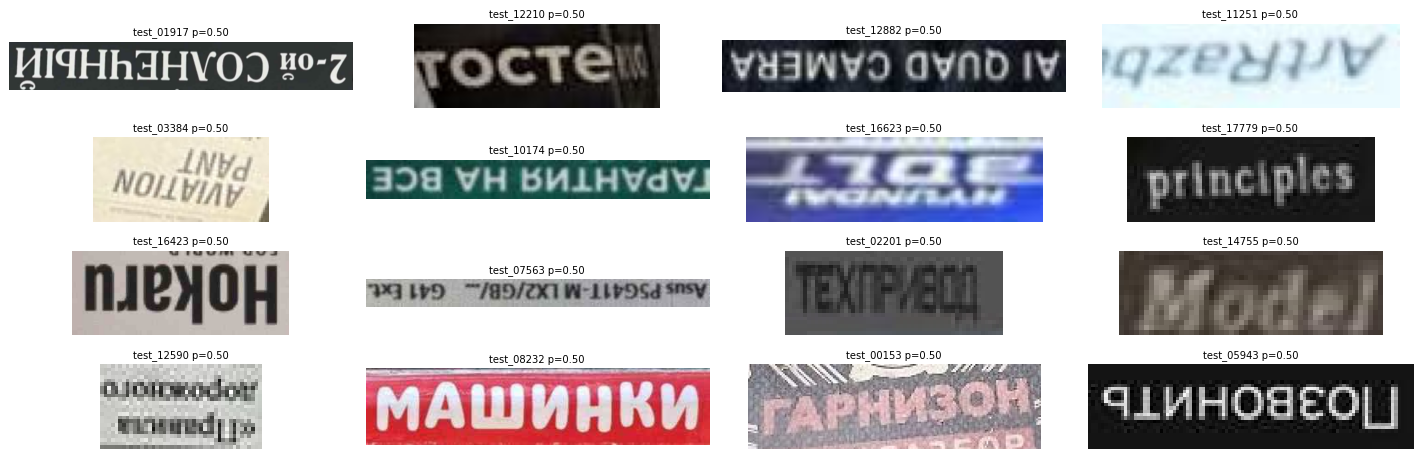

In [22]:
p = P_test['all_odd']
order = p.sort_values()
print('Самые уверенные "upright" (p_180 → 0)')
show_grid([f'{DATA}/{i}.png' for i in order.index[:16]], titles=[f'{i} p={v:.2f}' for i, v in order[:16].items()])
print('Самые уверенные "rot180" (p_180 → 1)')
show_grid([f'{DATA}/{i}.png' for i in order.index[-16:]], titles=[f'{i} p={v:.2f}' for i, v in order[-16:].items()])
mid = (p - .5).abs().sort_values().index[:16]
print('Самые неуверенные (p ≈ 0.5)')
show_grid([f'{DATA}/{i}.png' for i in mid], titles=[f'{i} p={p[i]:.2f}' for i in mid])

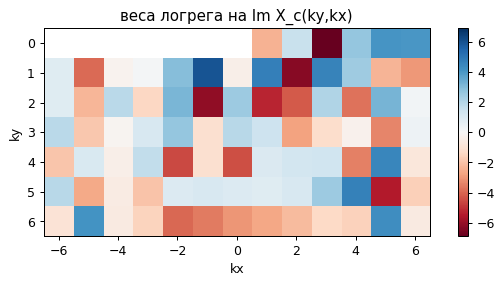

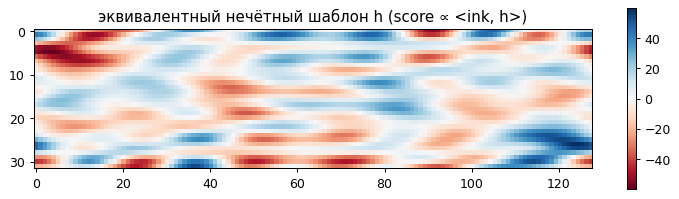

In [23]:
# Какие нечётные направления выучила линейная модель: веса по фазам 2D-гармоник
m, g = models['phase2d']
w = m[-1].coef_[0] / m[0].scale_
grid = np.full((KMAX + 1, 2 * KMAX + 1), np.nan); i = 0
for ky in range(0, KMAX + 1):
    for kx in range(-KMAX, KMAX + 1):
        if ky == 0 and kx <= 0: continue
        grid[ky, kx + KMAX] = w[i]; i += 1
plt.figure(figsize=(8, 3))
v = np.nanmax(np.abs(grid))
plt.imshow(grid, cmap='RdBu', vmin=-v, vmax=v, extent=[-KMAX - .5, KMAX + .5, KMAX + .5, -.5])
plt.colorbar(); plt.xlabel('kx'); plt.ylabel('ky'); plt.title('веса логрега на Im X_c(ky,kx)')
plt.show()

# Эквивалентный линейный фильтр в пространстве: w · Im X_c = <m, h>, где h — нечётная картинка
h = np.zeros((H, W)); yy, xx = np.mgrid[0:H, 0:W]; cy, cx = (H - 1) / 2, (W - 1) / 2; i = 0
for ky in range(0, KMAX + 1):
    for kx in range(-KMAX, KMAX + 1):
        if ky == 0 and kx <= 0: continue
        h += -w[i] * np.sin(2 * np.pi * (ky * (yy - cy) / H + kx * (xx - cx) / W)); i += 1
plt.figure(figsize=(10, 2.6)); plt.imshow(h, cmap='RdBu', vmin=-np.abs(h).max(), vmax=np.abs(h).max())
plt.title('эквивалентный нечётный шаблон h (score ∝ <ink, h>)'); plt.colorbar(); plt.show()

## 5b. H5: на реальных данных глобальную фазу «съедают» посторонние объекты

На сетке выше крайние предсказания почти все про **окклюдеры и перепады освещения**: тёмный угол, палец, блик, обрез вывески. Текст на них почти не влияет. Для глобальной низкочастотной фазы тёмное пятно в одном углу является огромной «нечётной» компонентой.

Проверяем:
1. Растёт ли уверенность $|2p-1|$ на реальных данных вместе с долей низкочастотной энергии (прокси «пятна или градиента»). На синтетике эффекта быть не должно.
2. Воспроизводится ли деградация на синтетике, если добавить туда окклюдеры и градиент освещения (помеха поворачивается вместе с картинкой, то есть это чистый шум, не связанный с меткой).
3. Помогает ли **high-pass карта чернил** $m=|x - G_\sigma * x|$, которая убирает «тела» пятен и плавную засветку.

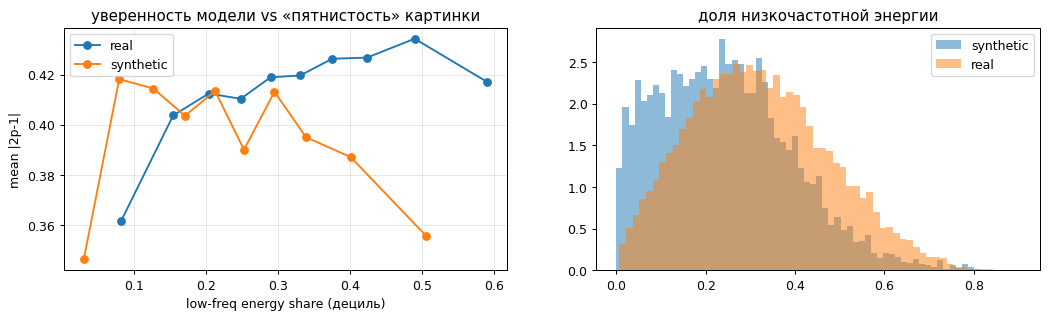

spearman(|2p-1|, lowfreq): real 0.052 | synth -0.004


In [24]:
def lowfreq_share(m):
    A = np.abs(np.fft.fft2(m - m.mean())) ** 2
    ky = np.abs(np.fft.fftfreq(m.shape[0], 1 / m.shape[0]))[:, None]; kx = np.abs(np.fft.fftfreq(m.shape[1], 1 / m.shape[1]))[None, :]
    return A[(ky <= 1) & (kx <= 2)].sum() / (A.sum() + 1e-9)

lf_real = np.array([lowfreq_share(m) for m in test_maps])
lf_syn = np.array([lowfreq_share(m) for m in syn_maps])
p_syn_all = models['all_odd'][0].predict_proba(np.hstack([F_up[k] for k in models['all_odd'][1]]))[:, 1]
conf_real, conf_syn = np.abs(2 * P_test['all_odd'].values - 1), np.abs(2 * p_syn_all - 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for lf, cf, lab in [(lf_real, conf_real, 'real'), (lf_syn, conf_syn, 'synthetic')]:
    q = pd.qcut(lf, 10, labels=False, duplicates='drop')
    ax[0].plot(pd.Series(lf).groupby(q).median(), pd.Series(cf).groupby(q).mean(), 'o-', label=lab)
ax[0].set_xlabel('low-freq energy share (дециль)'); ax[0].set_ylabel('mean |2p-1|'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title('уверенность модели vs «пятнистость» картинки')
ax[1].hist(lf_syn, bins=60, alpha=.5, density=True, label='synthetic'); ax[1].hist(lf_real, bins=60, alpha=.5, density=True, label='real')
ax[1].legend(); ax[1].set_title('доля низкочастотной энергии'); plt.show()
print('spearman(|2p-1|, lowfreq): real %.3f | synth %.3f' % (stats.spearmanr(conf_real, lf_real).correlation, stats.spearmanr(conf_syn, lf_syn).correlation))

In [25]:
from scipy.ndimage import gaussian_filter

def add_nuisance(img):
    # окклюдер (эллипс или полигон у края) и/или линейная засветка; помеха поворачивается вместе с картинкой
    a = np.asarray(img, np.float32).copy(); h, w = a.shape[:2]
    if random.random() < 0.5:
        yy, xx = np.mgrid[0:h, 0:w]
        cy = random.choice([0, h]) + random.uniform(-.3, .3) * h; cx = random.uniform(0, w)
        ry, rx = random.uniform(.4, 1.2) * h, random.uniform(.1, .5) * w
        mask = ((yy - cy) / ry) ** 2 + ((xx - cx) / rx) ** 2 < 1
        a[mask] = np.random.randint(0, 256, 3) * random.uniform(.3, 1)
    if random.random() < 0.5:
        g = np.linspace(-1, 1, w)[None, :] * random.uniform(-80, 80) + np.linspace(-1, 1, h)[:, None] * random.uniform(-60, 60)
        a = a + g[..., None]
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

syn_imgs_nz = [add_nuisance(im) for im in syn_imgs]

def ink_map_hp(img, H=H, W=W):
    x = np.asarray(img.convert('L').resize((W, H), Image.BILINEAR), np.float32) / 255.
    m = np.abs(x - gaussian_filter(x, sigma=H / 6, mode='reflect'))
    return np.clip(m / (np.percentile(m, 99) + 1e-3), 0, 1)

def feats_with(imgs, mapper):
    out = {'ODD_prof_y': [], 'ODD_prof_x': [], 'ODD_phase2d': []}
    for im in imgs:
        m = mapper(im)
        out['ODD_prof_y'].append(prof_feats(m.mean(1))); out['ODD_prof_x'].append(prof_feats(m.mean(0))); out['ODD_phase2d'].append(phase2d_feats(m))
    return {k: np.stack(v) for k, v in out.items()}

GRP = ['ODD_prof_y', 'ODD_prof_x', 'ODD_phase2d']
def fit_eval(Ftr_up, Fte_up, grp=GRP):
    # нечётные признаки: f(rot x) = -f(x), поэтому пары строим знаком
    Xtr = np.hstack([Ftr_up[k][tr_id] for k in grp]); Xte = np.hstack([Fte_up[k][te_id] for k in grp])
    m = odd_model().fit(np.vstack([Xtr, -Xtr]), np.r_[np.zeros(len(Xtr)), np.ones(len(Xtr))])
    p = m.predict_proba(np.vstack([Xte, -Xte]))[:, 1]; y = np.r_[np.zeros(len(Xte)), np.ones(len(Xte))]
    return 1 - brier_score_loss(y, p), roc_auc_score(y, p), m

FS = {('clean', 'ink'): {k: F_up[k] for k in GRP},
      ('nuis', 'ink'): feats_with(syn_imgs_nz, ink_map),
      ('clean', 'hp'): feats_with(syn_imgs, ink_map_hp),
      ('nuis', 'hp'): feats_with(syn_imgs_nz, ink_map_hp)}
rows = []
for mp in ['ink', 'hp']:
    for tr in ['clean', 'nuis']:
        for te in ['clean', 'nuis']:
            b, a, _ = fit_eval(FS[(tr, mp)], FS[(te, mp)])
            rows.append({'map': mp, 'train': tr, 'test': te, '1-Brier': b, 'AUC': a})
display(pd.DataFrame(rows).round(3))

,map,train,test,1-Brier,AUC
0,ink,clean,clean,0.798,0.756
1,ink,clean,nuis,0.713,0.601
2,ink,nuis,clean,0.784,0.716
3,ink,nuis,nuis,0.764,0.641
4,hp,clean,clean,0.798,0.752
5,hp,clean,nuis,0.729,0.637
6,hp,nuis,clean,0.779,0.694
7,hp,nuis,nuis,0.770,0.655


ink map : agree(prof_y, prof_x) on real = 0.513
hp  map : agree(prof_y, prof_x) on real = 0.515
hp_all_odd: самые уверенные upright


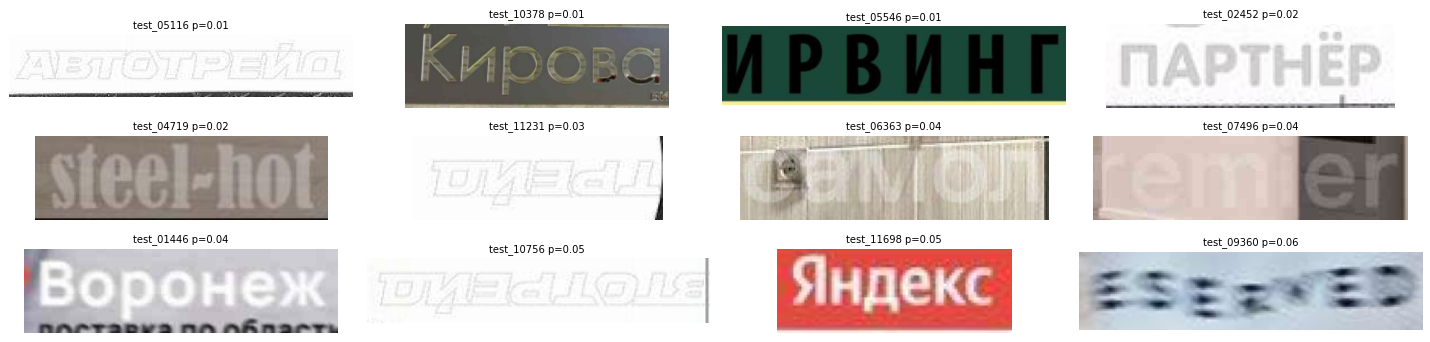

hp_all_odd: самые уверенные rot180


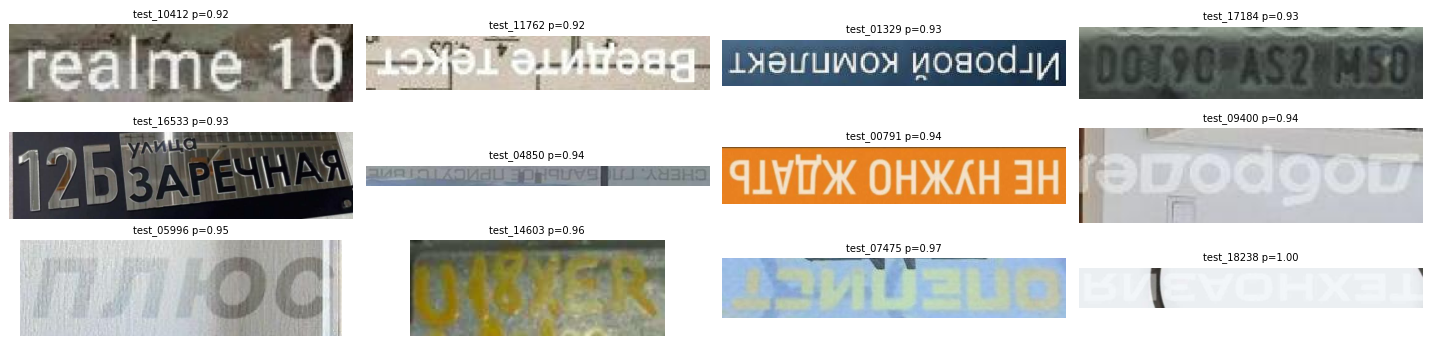

In [26]:
# hp-карта на реальном тесте: согласованность независимых осей и крайние примеры
F_test_hp = feats_with(test_imgs, ink_map_hp)
F_nz_hp = FS[('nuis', 'hp')]
def fit_on(Fs, grp):
    X = np.hstack([Fs[k] for k in grp]); return odd_model().fit(np.vstack([X, -X]), np.r_[np.zeros(len(X)), np.ones(len(X))])
m_y, m_x, m_all = fit_on(F_nz_hp, ['ODD_prof_y']), fit_on(F_nz_hp, ['ODD_prof_x']), fit_on(F_nz_hp, GRP)
P_test['hp_prof_y'] = m_y.predict_proba(F_test_hp['ODD_prof_y'])[:, 1]
P_test['hp_prof_x'] = m_x.predict_proba(F_test_hp['ODD_prof_x'])[:, 1]
P_test['hp_all_odd'] = m_all.predict_proba(np.hstack([F_test_hp[k] for k in GRP]))[:, 1]
print('ink map : agree(prof_y, prof_x) on real = %.3f' % agree(P_test.prof_y, P_test.prof_x))
print('hp  map : agree(prof_y, prof_x) on real = %.3f' % agree(P_test.hp_prof_y, P_test.hp_prof_x))
o = P_test['hp_all_odd'].sort_values()
print('hp_all_odd: самые уверенные upright'); show_grid([f'{DATA}/{i}.png' for i in o.index[:12]], titles=[f'{i} p={v:.2f}' for i, v in o[:12].items()])
print('hp_all_odd: самые уверенные rot180');  show_grid([f'{DATA}/{i}.png' for i in o.index[-12:]], titles=[f'{i} p={v:.2f}' for i, v in o[-12:].items()])

## 5c. H6: информация в **локальной** фазе (форма отдельных букв), а не в глобальной

Глобальные гармоники усредняют всю строку. Асимметрия же сидит в локальных элементах: засечки, «хвосты» у р/у/д, чаши у Р/Ь/Б, плоская базовая линия. Локальную фазу естественно ловят свёртки. Референс: крошечная CNN (около 40k параметров, вход 32×128) с **антисимметричной головой** $\mathrm{logit}(x)=f(x)-f(\mathrm{rot}\,x)$. Так $p(\mathrm{rot}\,x)=1-p(x)$ выполняется по построению. Обучаем только на синтетике с помехами.

_Holdout для CNN: отдельный набор рендеров (`syn_imgs_nz[te_id]`), но словарь и шрифты те же, поэтому оценка на синтетике оптимистична._

In [27]:
import torch, torch.nn as nn
torch.manual_seed(0)
dev = 'mps' if torch.backends.mps.is_available() else 'cpu'

def to_arr(img):
    x = np.asarray(img.convert('L').resize((128, 32), Image.BILINEAR), np.float32) / 255.
    return (x - x.mean()) / (x.std() + 1e-3)

# побольше синтетики для CNN (+ помехи)
N_CNN = 20000
cnn_imgs, cnn_case = [], []
while len(cnn_imgs) < N_CNN:
    t, c = rand_text(); im = render(t)
    if im is not None:
        cnn_imgs.append(add_nuisance(im) if random.random() < 0.6 else im); cnn_case.append(c)
cnn_case = np.array(cnn_case)
Xc = torch.tensor(np.stack([to_arr(im) for im in cnn_imgs]))[:, None]
Xsyn_te = torch.tensor(np.stack([to_arr(im) for im in syn_imgs_nz]))[:, None][te_id]   # holdout: другой набор слов/рендеров

class OrientNet(nn.Module):
    def __init__(s, c=(16, 32, 48)):
        super().__init__()
        L, ci = [], 1
        for co in c:
            L += [nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(), nn.MaxPool2d(2)]; ci = co
        s.f = nn.Sequential(*L, nn.Conv2d(ci, ci, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(ci, 1))
    def forward(s, x):
        return (s.f(x) - s.f(torch.flip(x, [2, 3]))).squeeze(1)

net = OrientNet().to(dev)
print('params:', sum(p.numel() for p in net.parameters()))
opt = torch.optim.AdamW(net.parameters(), 3e-3, weight_decay=1e-4)
EPOCHS, BS = 12, 256
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=EPOCHS * (N_CNN // BS + 1))
t0 = time.time()
for ep in range(EPOCHS):
    net.train(); perm = torch.randperm(N_CNN); tot = 0
    for i in range(0, N_CNN, BS):
        xb = Xc[perm[i:i + BS]]
        yb = (torch.rand(len(xb)) < .5).float()
        xb = torch.where(yb[:, None, None, None] > 0, torch.flip(xb, [2, 3]), xb)
        xb = xb * torch.where(torch.rand(len(xb), 1, 1, 1) < .5, -1., 1.)   # аугментация полярности
        loss = nn.functional.binary_cross_entropy_with_logits(net(xb.to(dev)), yb.to(dev))
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item() * len(xb)
    print(f'epoch {ep}: loss {tot / N_CNN:.4f}  ({time.time() - t0:.0f}s)')

params: 39601
epoch 0: loss 0.6791  (6s)
epoch 1: loss 0.5394  (10s)
epoch 2: loss 0.4106  (15s)
epoch 3: loss 0.3431  (19s)
epoch 4: loss 0.2926  (24s)
epoch 5: loss 0.2576  (28s)
epoch 6: loss 0.2299  (33s)
epoch 7: loss 0.2089  (37s)
epoch 8: loss 0.1859  (42s)
epoch 9: loss 0.1663  (46s)
epoch 10: loss 0.1546  (51s)
epoch 11: loss 0.1478  (55s)


consistency |p(x)+p(rot x)-1| = 1.1920929e-07


,AUC,1-Brier,1-Brier[lower],1-Brier[title],1-Brier[upper]
features,,,,,
hp all_odd logreg,0.655,0.77,NaN,NaN,NaN
tiny CNN (antisym),0.960,0.92,0.906,0.93,0.928


CPU inference: 0.362 ms/img (batch 256)


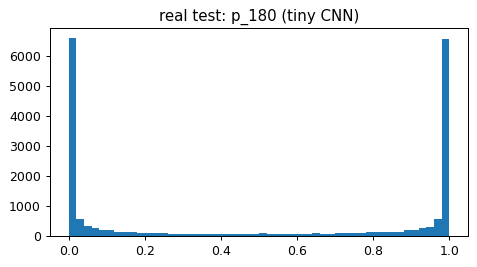

In [28]:
@torch.no_grad()
def cnn_predict(X, bs=1024, device=dev):
    net.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(torch.sigmoid(net.to(device)(X[i:i + bs].to(device))).cpu())
    return torch.cat(out).numpy()

pu = cnn_predict(Xsyn_te); pr = cnn_predict(torch.flip(Xsyn_te, [2, 3]))
p = np.r_[pu, pr]; y = np.r_[np.zeros(len(pu)), np.ones(len(pr))]; cs = np.r_[syn_case[te_id], syn_case[te_id]]
row = {'features': 'tiny CNN (antisym)', 'AUC': roc_auc_score(y, p), '1-Brier': 1 - brier_score_loss(y, p)}
for c in ['lower', 'title', 'upper']:
    s = cs == c; row[f'1-Brier[{c}]'] = 1 - brier_score_loss(y[s], p[s])
print('consistency |p(x)+p(rot x)-1| =', np.abs(pu + pr - 1).max())
hp_b, hp_a, _ = fit_eval(FS[('nuis', 'hp')], FS[('nuis', 'hp')])
display(pd.DataFrame([{'features': 'hp all_odd logreg', 'AUC': hp_a, '1-Brier': hp_b}, row]).set_index('features').round(3))

Xtest = torch.tensor(np.stack([to_arr(im) for im in test_imgs]))[:, None]
P_test['cnn'] = cnn_predict(Xtest)
t0 = time.time(); _ = cnn_predict(Xtest[:4096], bs=256, device='cpu'); dt = (time.time() - t0) / 4096
print(f'CPU inference: {dt * 1e3:.3f} ms/img (batch 256)')
plt.figure(figsize=(6, 3)); plt.hist(P_test.cnn, bins=50); plt.title('real test: p_180 (tiny CNN)'); plt.show()

,agree_with_cnn_real,spearman_with_cnn_real
prof_y,0.534,0.100
prof_x,0.581,0.227
phase2d,0.594,0.243
all_odd,0.609,0.297
hp_prof_y,0.520,0.076
hp_prof_x,0.585,0.242
hp_all_odd,0.591,0.260


CNN: самые уверенные upright


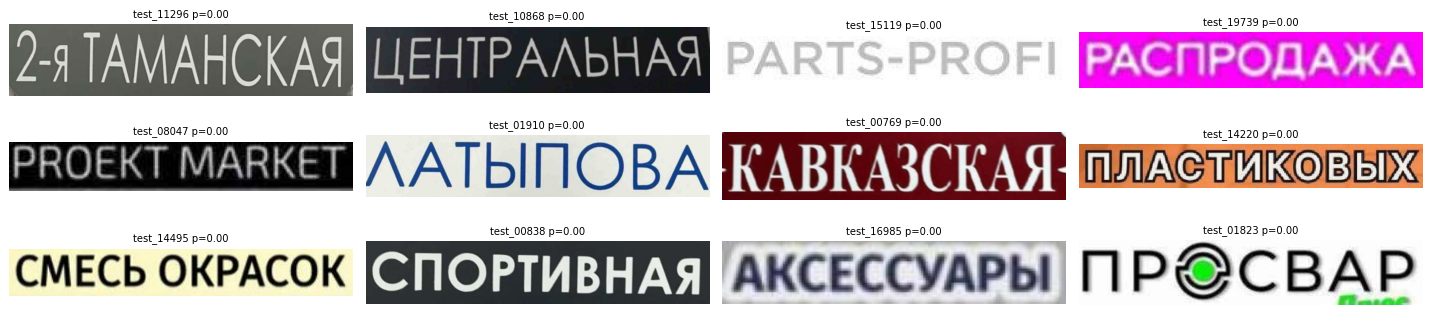

CNN: самые уверенные rot180


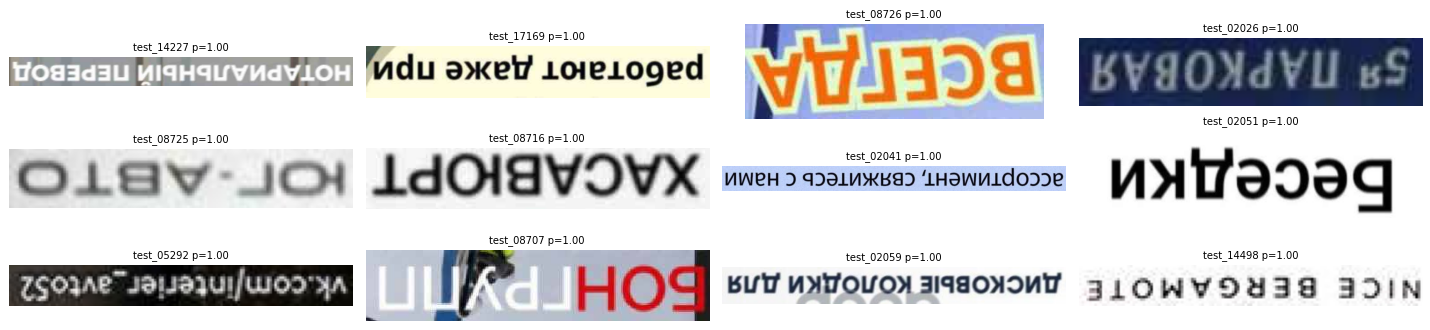

CNN: случайные примеры


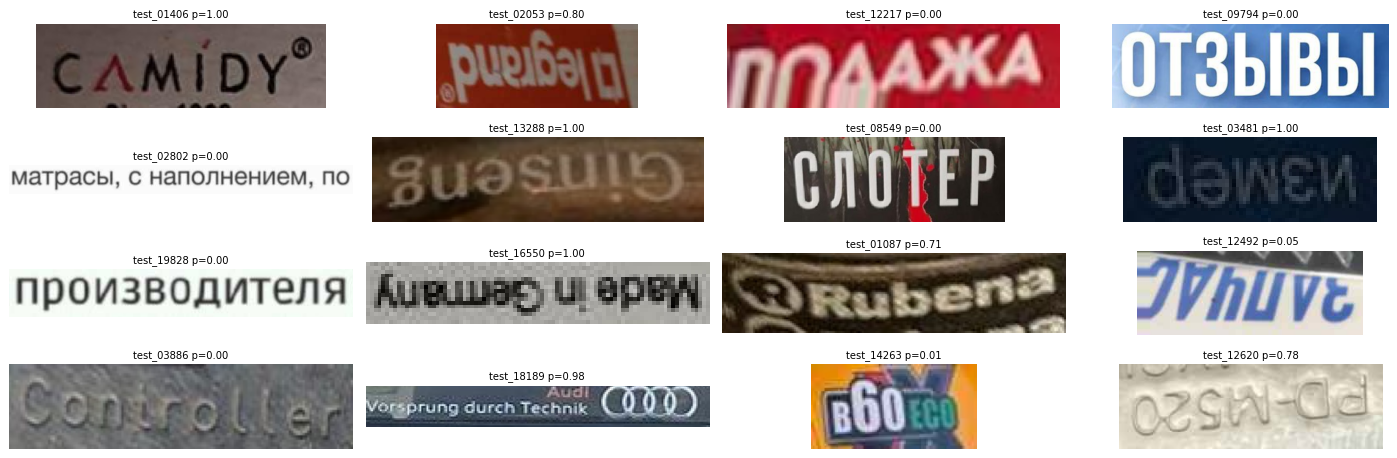

In [29]:
# независимые каналы на реальных данных: насколько каждый handcrafted-сигнал согласован с CNN
cols = ['prof_y', 'prof_x', 'phase2d', 'all_odd', 'hp_prof_y', 'hp_prof_x', 'hp_all_odd']
display(pd.DataFrame({'agree_with_cnn_real': [agree(P_test[c], P_test.cnn) for c in cols],
                      'spearman_with_cnn_real': [stats.spearmanr(P_test[c], P_test.cnn).correlation for c in cols]}, index=cols).round(3))
o = P_test['cnn'].sort_values()
print('CNN: самые уверенные upright'); show_grid([f'{DATA}/{i}.png' for i in o.index[:12]], titles=[f'{i} p={v:.2f}' for i, v in o[:12].items()])
print('CNN: самые уверенные rot180');  show_grid([f'{DATA}/{i}.png' for i in o.index[-12:]], titles=[f'{i} p={v:.2f}' for i, v in o[-12:].items()])
rnd = P_test.sample(16, random_state=3)
print('CNN: случайные примеры'); show_grid([f'{DATA}/{i}.png' for i in rnd.index], titles=[f'{i} p={v:.2f}' for i, v in rnd.cnn.items()])

## 6. Выводы

| # | Гипотеза | Результат |
|---|---|---|
| H0 | Амплитудный спектр не несёт информации об ориентации | **Подтверждена точно.** $\big||X|-|X_{rot}|\big|$ ≈ 4e-8. На синтетике `EVEN_amp` даёт AUC 0.500 (и логрег, и GBM), 1-Brier 0.75, то есть уровень константы. Мощность спектра, автокорреляция, гистограммы, aspect и цвет бесполезны. |
| H1 | Вся информация в фазе, а точнее в $\mathrm{Im}\,X_c$ (нечётная часть картинки) | **Подтверждена.** $X_c(\mathrm{rot}\,x)=\overline{X_c(x)}$ до машинной точности. Антисимметричная модель без intercept даёт $p(x)+p(\mathrm{rot}\,x)=1$ по построению. |
| — | Знаковые градиенты (HOG) без позиций путают поворот с инверсией полярности | **Подтверждена:** L1-расстояние гистограмм rot(x) и 1−x равно 7e-4, у rot(x) и x оно 0.12. Нужен вход, не зависящий от полярности, или аугментация полярностью. |
| H2 | Хватает низкочастотной **глобальной** фазы | **Сигнал слабый.** Лучший вариант на синтетике даёт AUC ≈ 0.77 и 1-Brier ≈ 0.80. Насыщение наступает при K≈6–8 гармониках, разрешение 8 и 32 px по высоте дают почти одно и то же. |
| H3 | Вертикальная асимметрия задаётся выносными элементами, КАПС симметричен | **В основном не подтверждена для кириллицы.** Медианный центроид ≈ 0 во всех регистрах, `prof_y` на `lower` не лучше, чем на `UPPER`. Горизонтальная (лево/право) асимметрия информативна не меньше. Лучше всего глобальная фаза работает на `Title` (1-Brier 0.85): заглавная буква слева даёт сильную глобальную асимметрию. |
| H5 | На реальных данных глобальную фазу «съедают» окклюдеры и засветка | **Подтверждена.** Крайние предсказания почти сплошь окклюдеры. Если добавить помехи в синтетику, AUC падает с 0.77 до ≈0.65. High-pass карта чернил помогает мало (≈+0.01 AUC). На реальном тесте независимые каналы `prof_y` и `prof_x` согласованы лишь на 0.51. |
| H6 | Информация в **локальной** фазе (форма букв), её ловят свёртки | **Подтверждена.** Антисимметричная CNN на 40k параметров, обученная только на синтетике, даёт на зашумлённой синтетике AUC 0.95 и 1-Brier ≈ 0.91, в том числе ≈0.92 на КАПСе. На реальном тесте распределение скоров резко бимодально, самые уверенные примеры визуально корректны, а handcrafted-каналы согласуются с ней лучше, чем друг с другом. Инференс ≈0.7 ms/img на CPU. |

**Доля перевёрнутых в тесте.** Оценка через $\mathbb E[s]$ по нескольким каналам даёт 0.47–0.51, то есть тест сбалансирован. Константа 0.5 даёт 1-Brier = 0.75, это нижняя планка.

**Что это значит для решения:**
1. Ручные частотные признаки (амплитуда, глобальная фаза) как основа модели бесперспективны: амплитуда доказуемо пуста, глобальная фаза слабая и неустойчива к помехам.
2. Правильная индуктивная структура такая: маленькая свёрточная сеть + **антисимметричная голова** $f(x)-f(\mathrm{rot}\,x)$ (симметрия задачи бесплатно, TTA не нужен) + вход, не зависящий от полярности, или аугментация полярностью.
3. Главный риск для Brier — **переуверенность**: гистограмма скоров CNN прижата к 0 и 1, а на случайной выборке есть уверенные ошибки. Нужны temperature scaling (например, на реалистичной отложенной синтетике) и клиппинг.
4. Качество упирается в домен-гэп синтетики. Дальше стоит добавить реальные фоны и кропы сцен, изогнутый и рукописный текст, окклюдеры, больше шрифтов, а также открытые OCR-датасеты с известной ориентацией.